# 03 — Regime models (`EXP-H02`)

## 1. Objective

Test whether filtered two-state regime probabilities improve horizon-return density forecasts relative to the unconditional distribution retained by H1.

## 2. Hypothesis

Filtered probabilities $\pi_{t\mid t}$ from a two-state Gaussian HMM improve the 5-, 15-, and 60-minute log-return density relative to that unconditional benchmark.

## 3. Null

The regime mixture adds no density-forecast value on that pre-registered family.

## 4. Information set

The filter sees only one-minute log returns known at or before the decision time. A return enters at the close that reveals it, so it is not part of the horizon label that starts at that close. Probabilities are the forward filter \(\pi_{t\mid t}\). Smoothed state probabilities are used only inside Baum-Welch on the training window and are not a forecast input. No same-bar high or low, and no local clock.

## 5. Dataset and version

`research/registry/datasets/btcusdt-1m.json`, loaded from `s3://trading-data-centheos` with AWS profile `trading`.

## 6. Data-quality checks

The dataset freeze counts duplicates, off-grid rows, bad prices, inconsistent OHLC, and missing minutes. A missing minute resets the Markov chain. Labels with no filtered probability are dropped and counted.

## 7. Label definition

`log(close[t + h]) - log(close[t])` only when both minute bars exist. A gap does not become a longer return. First-passage labels are not scored: the barrier definition is still an open question, so this experiment is density only.

## 8. Baseline

The nested baseline is the unconditional distribution recorded by `EXP-H01`. Student-t is that baseline when H1 retains it or its development validation selects it. Rejection of Student-t leaves Gaussian. An H1 record with no result scores Gaussian. This notebook does not treat the comparison as confirmation.

## 9. Model / method

Two-state Gaussian HMM on one-minute returns, ordered so state 0 has the lower variance. Horizon densities are a mixture of the same family as the H1 benchmark, weighted by the filtered probability at the decision time. A state without a usable effective sample fails that window rather than collapsing to one regime.

## 10. Training / validation / test split

Rolling 24-month train and 6-month validation windows, stepped by 6 months. The final 12 calendar months are sealed. A label whose outcome falls beyond a block boundary leaves that block.

## 11. Experiment configuration

`research.protocol.H2_CONFIG`. Its digest is printed below.


In [1]:
import os
import sys
from dataclasses import asdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

root = Path.cwd().resolve()
while root != root.parent and not (root / "research" / "__init__.py").exists():
    root = root.parent
if not (root / "research" / "__init__.py").exists():
    raise RuntimeError("open this notebook from the trading repository")
os.chdir(root)
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
os.environ.setdefault("AWS_PROFILE", "trading")
os.environ.setdefault("AWS_DEFAULT_REGION", "ap-southeast-2")
os.environ.setdefault("DATA_STORE", "s3")
os.environ.setdefault("S3_BUCKET", "trading-data-centheos")
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:.6g}".format)

from research.registry import config_digest, load_record
from research.report import (
    calibration_summary,
    confirmation_blockers,
    model_colors,
    plain_english_result,
    plot_advantage_by_origin,
    plot_density_panels,
    plot_pit_qq,
    plot_score_levels,
    plot_shortfall,
    plot_var_hit_rates,
    quality_table,
    record_development_decision,
    score_reading,
)

## 5–6. Dataset and data quality

The frozen manifest is reloaded and verified. Every audit exclusion is counted in the table.

In [2]:
from research.evaluate import align_to_frozen_dataset
from research.load import load_research_bars
from research.manifest import load_manifest
from research.protocol import H2_CONFIG

frozen = load_manifest(root / "research" / "registry" / "datasets" / "btcusdt-1m.json")
bars, objects = load_research_bars(
    venue=H2_CONFIG["venue"],
    symbol=H2_CONFIG["symbol"],
    timeframe=H2_CONFIG["timeframe"],
    bucket=H2_CONFIG["bucket"],
    profile=H2_CONFIG["profile"],
    region=H2_CONFIG["region"],
)
kept, report, appended = align_to_frozen_dataset(bars, frozen, objects)
print(f"dataset {frozen.dataset_id} digest {frozen.digest}")
print(f"frozen window {frozen.start} to {frozen.end}; collector rows after the freeze excluded: {appended}")
display(quality_table({H2_CONFIG["symbol"]: report}))

Excluded 2406 collector rows after frozen end 2026-10-17T10:43:00+00:00; ohlcv/binance/BTCUSDT/1m/2026.parquet etag b67bbf4dddd1bcb2658bac4d361452ec -> 5be7cba74886ec370c6ed58fe5cef3f0, size 5482639 -> 5544672


dataset btcusdt-1m digest c1192eca8fa673c386b4ff3aad751f4f2d4895e2b02d7b693a42aac1ecd28188
frozen window 2020-01-01T00:00:00+00:00 to 2026-10-17T10:43:00+00:00; collector rows after the freeze excluded: 2406


,rows_in,rows_kept,duplicate_timestamps,off_grid_timestamps,nonpositive_prices,inconsistent_ohlc,missing_minutes,largest_gap_minutes
series,,,,,,,,
BTCUSDT,3573284,3573284,0,0,0,0,0,1


## 12–17. Evaluation

The evaluation compares the filtered two-state regime mixture with the unconditional density named by H1 at every rolling origin. The null is rejected only when the mixture has a positive mean and median log-score advantage at every horizon.

- **12. Statistical evaluation.** Mean log score per walk-forward origin, PIT, and VaR coverage on the fixed model-by-horizon family.
- **13. Economic evaluation.** None. This hypothesis is predictive only.
- **14. Calibration.** PIT QQ and Bonferroni-adjusted VaR coverage, below.
- **15. Ablation.** The nested sequence is listed in §9.
- **16. Robustness.** Every rolling origin and every registered horizon must agree. A change of configuration is a new experiment.
- **17. Failure analysis.** Failed windows, exclusions, and gaps are counted and printed. A failed window is never scored as zero.

In [3]:
from research.evaluate import evaluate_h2, h2_development_decision, h2_log_score_comparison, h2_var_coverage_family

CONFIG = H2_CONFIG
EXPERIMENT_ID = "EXP-H02"
RECORD_PATH = root / "research" / "registry" / "EXP-H02.json"
DATASET_ID, DATASET_DIGEST = frozen.dataset_id, frozen.digest
h1_record = load_record(root / "research" / "registry" / "EXP-H01.json")
print("configuration digest:", config_digest(CONFIG))
print(f"H1 status={h1_record.status} result={h1_record.result} decision={h1_record.decision or '(blank)'}")
evaluation = evaluate_h2(kept["close"], h1_record, CONFIG)
if evaluation.sealed_access:
    raise RuntimeError("development notebook read the sealed test")
comparison = h2_log_score_comparison(evaluation.scores)
coverage = h2_var_coverage_family(evaluation.scores)
verdict = h2_development_decision(comparison, evaluation.benchmark).iloc[0]
BENCHMARK = evaluation.benchmark
CANDIDATES = ("regime_mixture",)
MODELS = (BENCHMARK, *CANDIDATES)
LABELS = {"gaussian": "Gaussian (H1)", "student_t": "Student-t (H1)", "regime_mixture": "regime mixture"}
ALPHA = float(CONFIG["var_alpha"])
QUESTION = "Do filtered calm/volatile regime probabilities improve the BTCUSDT return density beyond the unconditional H1 density?"
GATE_H1_RECORD = h1_record
GATE_OBJECTS = ()
print(
    f"benchmark {BENCHMARK} (resolved={evaluation.benchmark_resolved}); gap resets {evaluation.gap_resets}; "
    f"alignment exclusions {evaluation.alignment_exclusions}; failed windows {len(evaluation.failures)}; "
    f"sealed access {evaluation.sealed_access}"
)

configuration digest: c4d73024ca14d5d15ec0ff25106a599b2fb15114357a391d34dbbf5dba3b5c4e
H1 status=Exploratory result=student_t decision=(blank)


Dropped 1 labels with no filtered regime probability
Dropped 1 labels with no filtered regime probability
Dropped 1 labels with no filtered regime probability
HMM probability underflowed to zero and was floored at 1.0e-12
HMM probability underflowed to zero and was floored at 1.0e-12
HMM probability underflowed to zero and was floored at 1.0e-12
HMM probability underflowed to zero and was floored at 1.0e-12
HMM probability underflowed to zero and was floored at 1.0e-12
HMM probability underflowed to zero and was floored at 1.0e-12


benchmark student_t (resolved=True); gap resets 0; alignment exclusions 3; failed windows 0; sealed access False


## How to read the scores

The first table compares each candidate with the benchmark at every horizon.

- `mean_advantage` and `median_advantage` are the candidate's mean log score minus the benchmark's, in nats per validation return. Positive means the candidate put more probability on what actually happened.
- `density_change_pct` restates the mean advantage as a percentage change in geometric-mean forecast density. It is a forecast-quality measure, not a trading return.
- `origins_ahead` counts the walk-forward origins where the candidate won.

The second table is the same advantage at each origin. The third is tail calibration: `median_var_hit_rate` should be close to `var_target`, and `coverage_rejected` is true when the Bonferroni-adjusted VaR test rejects that model. These cells use the scores already computed. They do not refit a model or read the sealed year.

In [4]:
reading, per_origin = score_reading(evaluation.scores, benchmark=BENCHMARK, candidates=CANDIDATES)
calibration = calibration_summary(evaluation.scores, coverage, alpha=ALPHA)
print(f"Log-score advantage over {LABELS[BENCHMARK]} (positive means the candidate forecast better)")
display(reading)
print("Advantage at each walk-forward origin (nats)")
display(per_origin)
print(f"Tail calibration against the {ALPHA:.0%} VaR")
display(calibration)
if evaluation.failures:
    print("Failed windows (excluded, not counted as zero):")
    display(pd.DataFrame(evaluation.failures))

Log-score advantage over Student-t (H1) (positive means the candidate forecast better)


,horizon_minutes,candidate,benchmark,mean_advantage,median_advantage,min_advantage,max_advantage,origins_ahead,origins,density_change_pct,benchmark_score,candidate_score
0,5,regime_mixture,student_t,0.120553,0.11415,0.0732209,0.174532,7,7,12.8121,5.10812,5.22867
1,15,regime_mixture,student_t,0.10515,0.09978,0.067858,0.1516,7,7,11.0877,4.57412,4.67927
2,60,regime_mixture,student_t,0.0797072,0.0720581,0.0522858,0.111774,7,7,8.29699,3.88713,3.96684


Advantage at each walk-forward origin (nats)


candidate       regime_mixture                    
horizon_minutes             5         15        60
origin                                            
20220101               0.11415   0.09978 0.0720581
20220701              0.146778  0.124187 0.0914939
20230101              0.174532    0.1516  0.111774
20230701              0.150054  0.125905 0.0945592
20240101             0.0884289 0.0797547 0.0643008
20240701             0.0732209  0.067858 0.0522858
20250101             0.0967078 0.0869662 0.0714784

Tail calibration against the 5% VaR


,horizon_minutes,model,median_var_hit_rate,pit_ks_pvalue,expected_shortfall,realised_shortfall,bonferroni_var_pvalue,var_target,coverage_rejected
0,5,regime_mixture,0.0333647,0,-0.00387178,-0.00408447,0,0.05,True
1,5,student_t,0.0307173,0,-0.00439278,-0.00469007,0,0.05,True
2,15,regime_mixture,0.0362544,0,-0.00658482,-0.00723758,9.67369e-251,0.05,True
3,15,student_t,0.0345362,0,-0.00742321,-0.007859,1.31174e-319,0.05,True
4,60,regime_mixture,0.0362568,0,-0.013105,-0.0149689,1.38187e-250,0.05,True
5,60,student_t,0.039684,0,-0.0146878,-0.015212,3.76693e-138,0.05,True


## Development plots

1. Candidate minus benchmark mean log score at each origin. Bars above zero are wins. A result needs wins that are consistent across origins and horizons, not one large bar.
2. Mean log score levels, so the gap can be judged against the score itself.
3. Share of validation returns below each model's VaR. The black line is the registered target. Above the line, the model understates tail risk. Below it, the model overstates tail risk.
4. Model expected shortfall against the realised mean of the returns that breached VaR. Points below the diagonal mean the realised tail was worse than forecast.

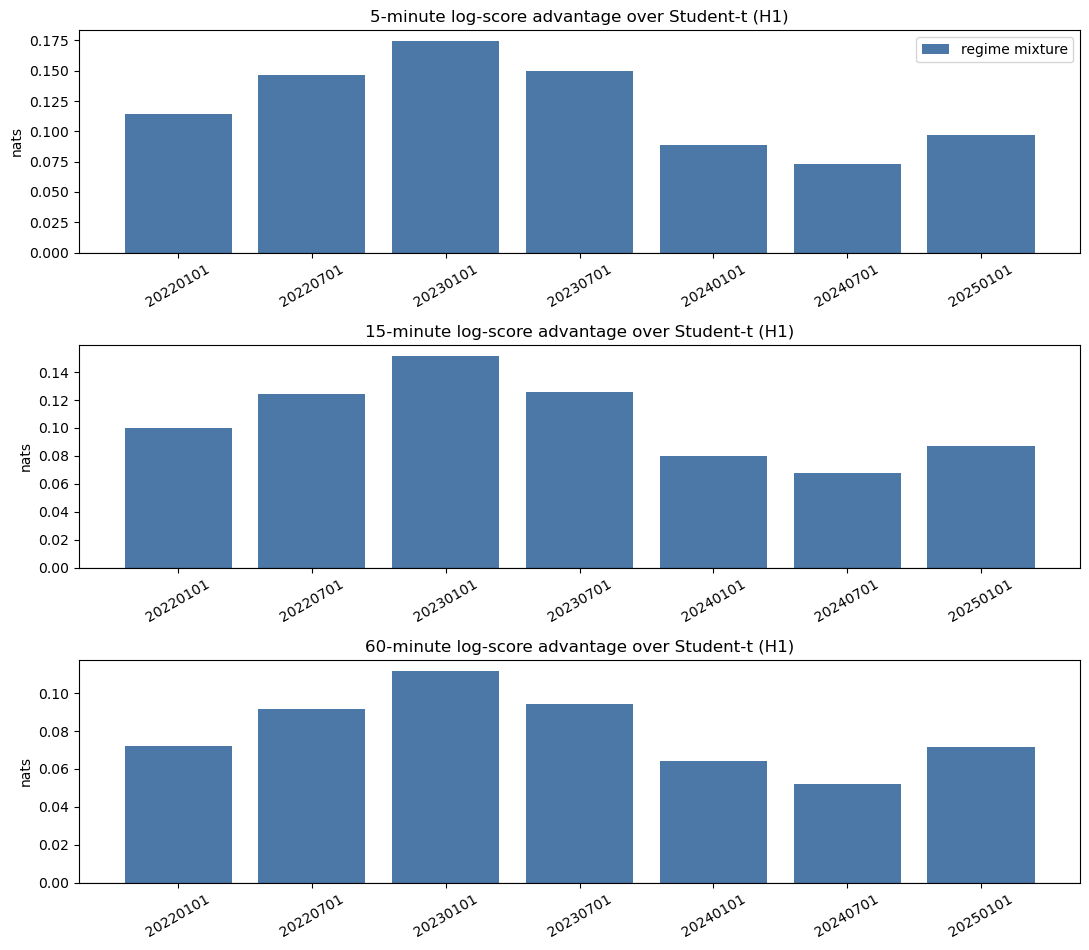

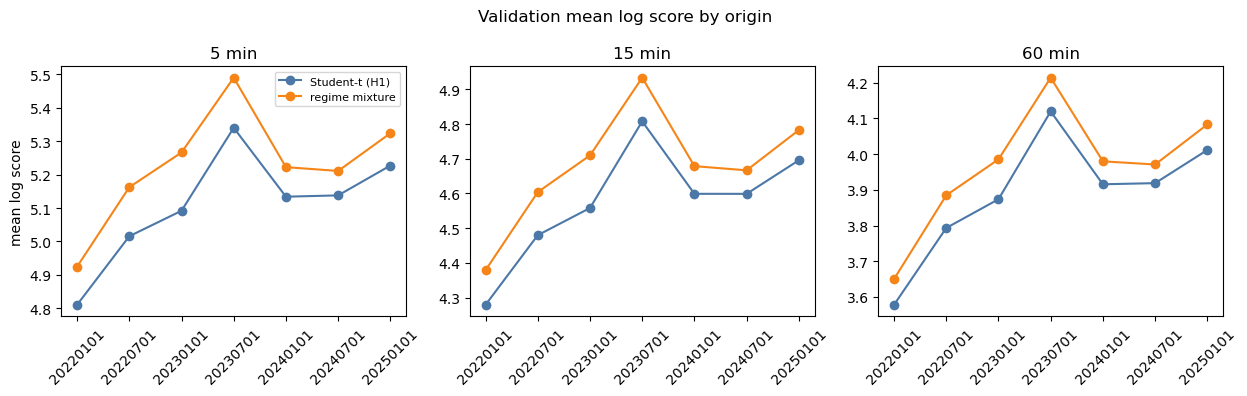

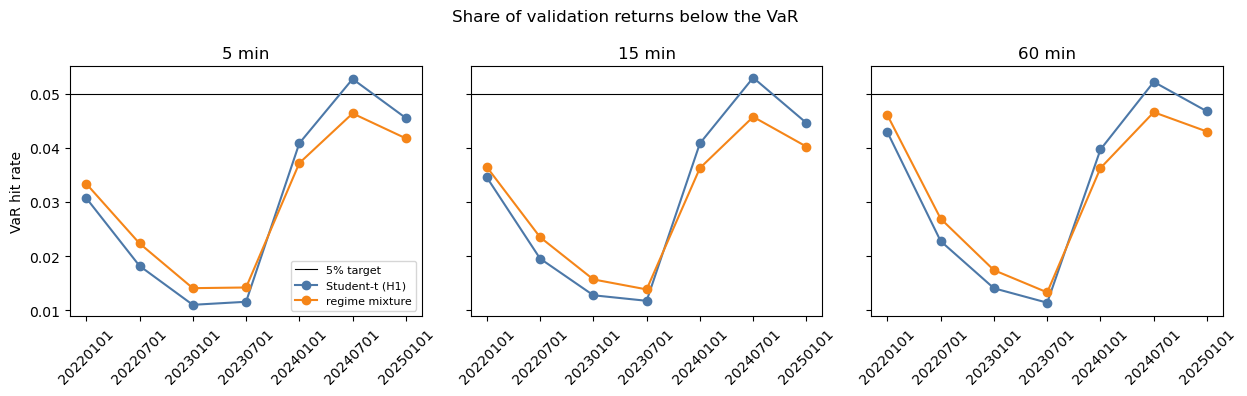

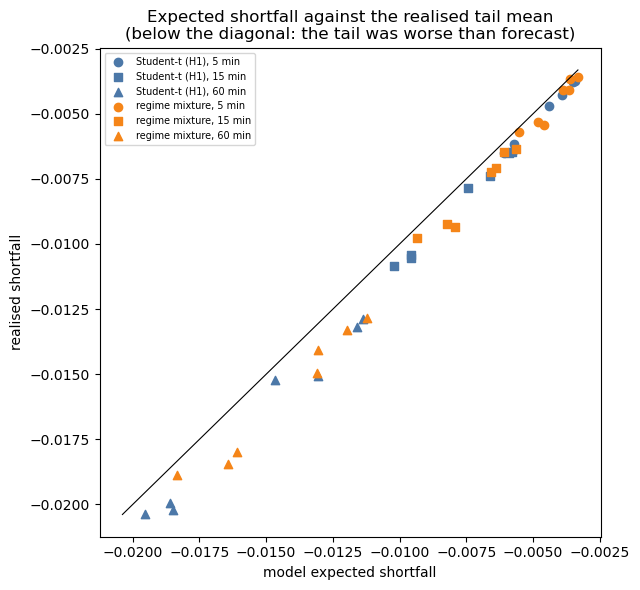

In [5]:
plot_advantage_by_origin(evaluation.scores, benchmark=BENCHMARK, candidates=CANDIDATES, labels=LABELS)
plt.show()
plot_score_levels(evaluation.scores, models=MODELS, labels=LABELS)
plt.show()
plot_var_hit_rates(evaluation.scores, models=MODELS, alpha=ALPHA, labels=LABELS)
plt.show()
plot_shortfall(evaluation.scores, models=MODELS, labels=LABELS)
plt.show()

## Calibration diagnostics

The probability integral transform (PIT) of a well-calibrated density is uniform. Each panel plots PIT quantiles against uniform quantiles. The diagonal is perfect calibration. Faint lines are individual origins and heavy lines are their mean. An S-shaped curve means the tails carry the wrong amount of probability. A candidate improves calibration only if its heavy line sits closer to the diagonal than the benchmark's.

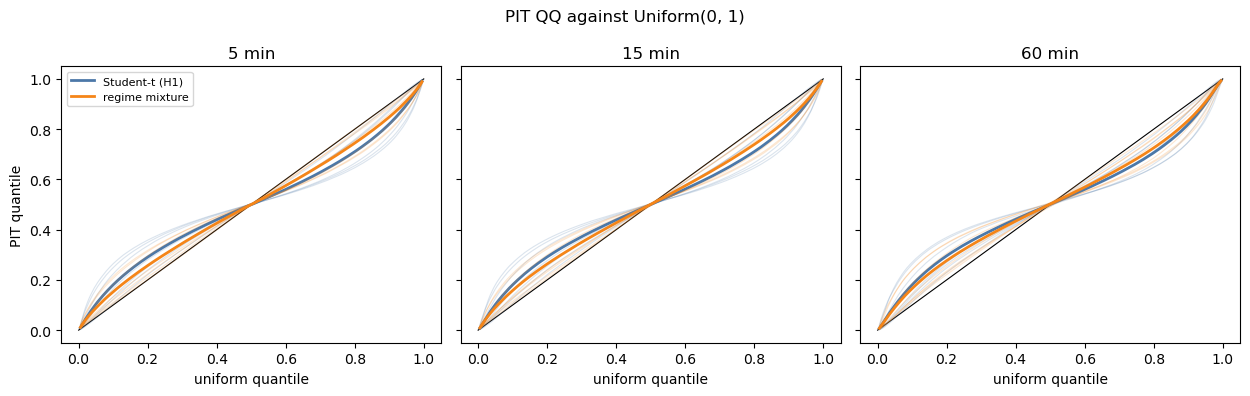

In [6]:
plot_pit_qq(evaluation.pit_qq, models=MODELS, labels=LABELS)
plt.show()

## Fitted densities

One two-state HMM is fitted to all development minutes, then the horizon densities. This shows the shape, not the rolling-origin models scored above. State 0 is the calm, lower-variance state. The histogram of the filtered probability shows how often the filter uses the volatile state. The density panels show the H1 density, each state's density, and mixtures with the volatile-state weight fixed at 0.1, 0.5, and 0.9. The top row is the body. The bottom row is the log-scale tail. This cell refits the HMM, so it is slower than the cells above.

fitting a two-state HMM on 3047039 development minutes; sealed_minutes_excluded=526244
iterations=20 converged=True gap_resets=0 filter_gap_resets=0
state 0 mean=7.04574e-07 std=0.000434077 stay=0.979
state 1 mean=1.4286e-06 std=0.00172135 stay=0.939
filtered P(state 1): mean=0.245 q10=0.008 q50=0.021 q90=0.954 stationary=0.256


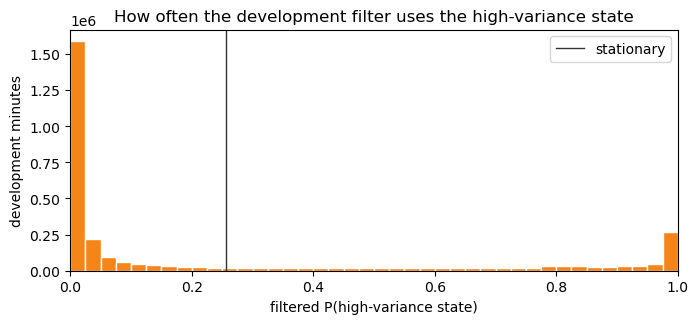

5 min dropped 1 labels with no filtered probability
5 min n=3047034 held_out=526244 dropped=1 student_t df=4.03 loc=4.45008e-06 scale=0.00146914
  state 0 df=4.11 loc=2.79091e-06 scale=0.000984594
  state 1 df=4.07 loc=9.54955e-06 scale=0.0024314
15 min dropped 1 labels with no filtered probability
15 min n=3047024 held_out=526244 dropped=1 student_t df=4.05 loc=1.33477e-05 scale=0.00247682
  state 0 df=4.12 loc=9.10652e-06 scale=0.00173378
  state 1 df=4.08 loc=2.63829e-05 scale=0.00400721
60 min dropped 1 labels with no filtered probability
60 min n=3046979 held_out=526244 dropped=1 student_t df=4.08 loc=5.33983e-05 scale=0.00484269
  state 0 df=4.16 loc=4.13815e-05 scale=0.0036519
  state 1 df=4.13 loc=9.03313e-05 scale=0.00747635


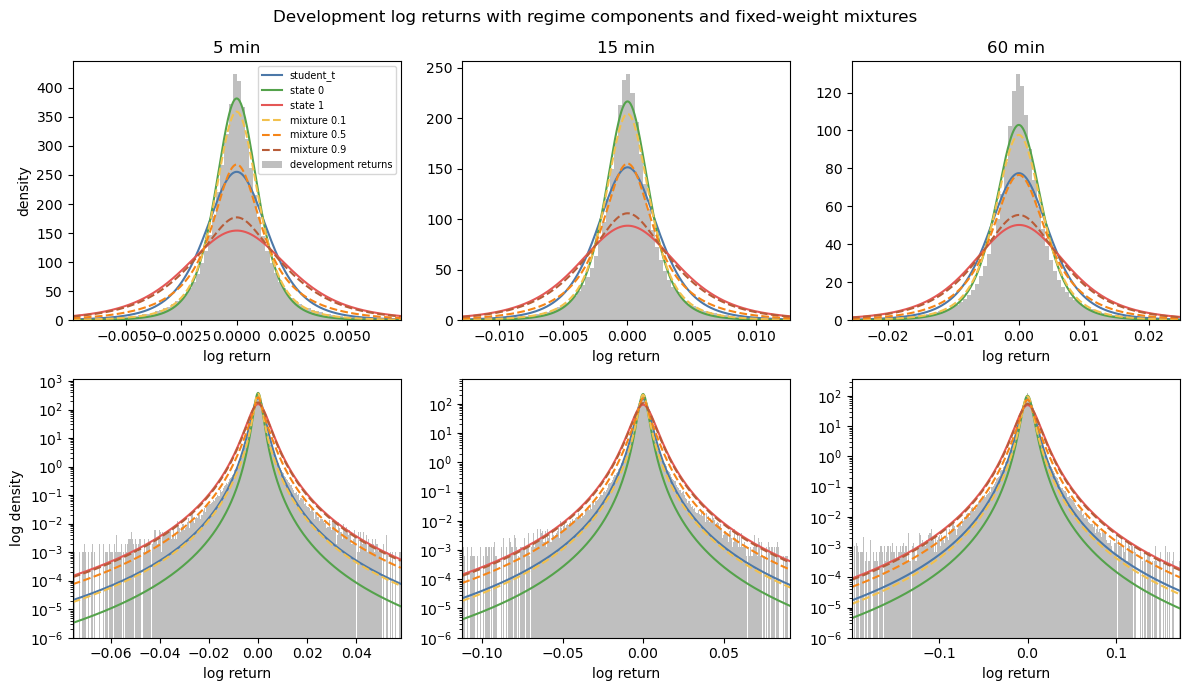

In [7]:
import math

import matplotlib.pyplot as plt
import numpy as np

from research.distributions import fit_gaussian, fit_student_t
from research.regimes import (
    fit_clocked_gaussian_hmm,
    fit_regime_densities,
    filtered_probability_frame,
    minute_returns_known_at_close,
)
from research.returns import horizon_log_returns
from research.splits import development_returns

if evaluation.sealed_access:
    raise RuntimeError("development notebook read the sealed test")
benchmark = evaluation.benchmark
if benchmark not in {"gaussian", "student_t"}:
    raise RuntimeError(f"fitted densities need a gaussian or student_t benchmark, got {benchmark}")
horizons = [int(value) for value in H2_CONFIG["horizons_minutes"]]
scored_horizons = sorted(int(value) for value in evaluation.scores["horizon_minutes"].unique())
if sorted(horizons) != scored_horizons:
    raise RuntimeError(f"fitted-density horizons {horizons} do not match scored horizons {scored_horizons}")

minute_returns, _ = minute_returns_known_at_close(kept["close"])
sealed_minutes = int((minute_returns.index >= evaluation.boundary).sum())
development_minutes = minute_returns.loc[minute_returns.index < evaluation.boundary]
if development_minutes.empty:
    raise RuntimeError("no development minute returns are available before the sealed boundary")
if sealed_minutes == 0:
    raise RuntimeError("fitted-density HMM held out no sealed minutes")
print(
    f"fitting a two-state HMM on {len(development_minutes)} development minutes; "
    f"sealed_minutes_excluded={sealed_minutes}"
)
fitted = fit_clocked_gaussian_hmm(
    development_minutes,
    max_iterations=int(H2_CONFIG["em_iterations"]),
    tolerance=float(H2_CONFIG["em_tolerance"]),
)
probabilities, filter_gap_resets = filtered_probability_frame(fitted.model, development_minutes)
if len(probabilities) != len(development_minutes):
    raise RuntimeError("filtered probabilities do not match the development minutes")
high_probability = probabilities["state_1"].to_numpy(dtype=float)
if not np.isfinite(high_probability).all() or (high_probability < 0).any() or (high_probability > 1).any():
    raise RuntimeError("filtered high-variance probability left [0, 1]")
leave_low = float(fitted.model.transitions[0, 1])
leave_high = float(fitted.model.transitions[1, 0])
movement = leave_low + leave_high
if movement <= 0.0:
    raise RuntimeError("HMM has no probability of leaving either state")
stationary_high = leave_low / movement
print(
    f"iterations={fitted.iterations} converged={fitted.converged} "
    f"gap_resets={fitted.gap_resets} filter_gap_resets={filter_gap_resets}"
)
print(
    f"state 0 mean={fitted.model.means[0]:.6g} std={math.sqrt(fitted.model.variances[0]):.6g} "
    f"stay={fitted.model.transitions[0, 0]:.3f}"
)
print(
    f"state 1 mean={fitted.model.means[1]:.6g} std={math.sqrt(fitted.model.variances[1]):.6g} "
    f"stay={fitted.model.transitions[1, 1]:.3f}"
)
print(
    "filtered P(state 1): "
    f"mean={float(high_probability.mean()):.3f} "
    f"q10={float(np.quantile(high_probability, 0.10)):.3f} "
    f"q50={float(np.quantile(high_probability, 0.50)):.3f} "
    f"q90={float(np.quantile(high_probability, 0.90)):.3f} "
    f"stationary={stationary_high:.3f}"
)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(high_probability, bins=40, range=(0.0, 1.0), color="#f58518", edgecolor="white")
ax.axvline(stationary_high, color="0.2", linewidth=1.0, label="stationary")
ax.set_xlim(0.0, 1.0)
ax.set_xlabel("filtered P(high-variance state)")
ax.set_ylabel("development minutes")
ax.set_title("How often the development filter uses the high-variance state")
ax.legend()
fig.tight_layout()
plt.show()

mixture_weights = (0.1, 0.5, 0.9)
mixture_color = {0.1: "#f2c14e", 0.5: "#f58518", 0.9: "#b85c38"}
state_color = {"state 0": "#54a24b", "state 1": "#e45756", benchmark: "#4c78a8"}

def fixed_mixture_density(components, weight_high, grid):
    if not 0.0 < weight_high < 1.0:
        raise ValueError(f"mixture weight must be strictly inside (0, 1), got {weight_high}")
    logged = np.column_stack(
        [
            math.log(1.0 - weight_high) + components[0].log_density(grid),
            math.log(weight_high) + components[1].log_density(grid),
        ]
    )
    if not np.isfinite(logged).all():
        raise RuntimeError("regime mixture log density is not finite")
    peak = np.max(logged, axis=1, keepdims=True)
    return np.exp(peak + np.log(np.sum(np.exp(logged - peak), axis=1, keepdims=True))).ravel()

def component_text(model):
    if benchmark == "gaussian":
        return f"mean={model.mean:.6g} std={math.sqrt(model.variance):.6g}"
    return f"df={model.df:.2f} loc={model.loc:.6g} scale={model.scale:.6g}"

failures = []
legend_axis = None
fig, axes = plt.subplots(2, len(horizons), figsize=(12, 7))
for column, horizon in enumerate(horizons):
    built = horizon_log_returns(kept["close"], int(horizon))
    sample, held_out = development_returns(built.returns, int(horizon), evaluation.boundary)
    if held_out == 0:
        raise RuntimeError(f"{horizon}-minute plot held out no sealed labels")
    try:
        aligned = probabilities.reindex(sample.index)
        missing = aligned.isna().any(axis=1)
        dropped = int(missing.sum())
        labels = sample.loc[~missing]
        weights = aligned.loc[~missing].to_numpy(dtype=float)
        if dropped:
            print(f"{horizon} min dropped {dropped} labels with no filtered probability")
        if len(labels) < 30:
            raise RuntimeError(f"{horizon}-minute density fit has only {len(labels)} aligned labels")
        values = labels.to_numpy(dtype=float)
        if benchmark == "gaussian":
            unconditional = fit_gaussian(values)
        else:
            unconditional = fit_student_t(values)
        components = fit_regime_densities(values, weights, benchmark)
        body = np.quantile(values, [0.005, 0.995])
        tails = np.quantile(values, [0.00001, 0.99999])
        print(
            f"{horizon} min n={len(values)} held_out={held_out} dropped={dropped} "
            f"{benchmark} {component_text(unconditional)}"
        )
        print(f"  state 0 {component_text(components[0])}")
        print(f"  state 1 {component_text(components[1])}")
        for row, (window, log_scale) in enumerate(((body, False), (tails, True))):
            ax = axes[row, column]
            bin_width = (float(body[1]) - float(body[0])) / 80
            bins = int(np.ceil((float(window[1]) - float(window[0])) / bin_width))
            bins = min(max(bins, 80), 400)
            counts, edges = np.histogram(values, bins=bins, range=(float(window[0]), float(window[1])))
            width = np.diff(edges)
            density = counts / (len(values) * width)
            ax.bar(
                edges[:-1],
                np.where(density > 0, density, np.nan),
                width=width,
                align="edge",
                color="0.75",
                label="development returns",
            )
            grid = np.linspace(float(window[0]), float(window[1]), 500)
            curve_peaks = [float(np.nanmax(density))]
            unconditional_density = np.exp(unconditional.log_density(grid))
            ax.plot(grid, unconditional_density, color=state_color[benchmark], label=benchmark)
            curve_peaks.append(float(np.nanmax(unconditional_density)))
            for state, component in enumerate(components):
                name = f"state {state}"
                state_density = np.exp(component.log_density(grid))
                ax.plot(grid, state_density, color=state_color[name], label=name)
                curve_peaks.append(float(np.nanmax(state_density)))
            for weight in mixture_weights:
                mixture_density = fixed_mixture_density(components, weight, grid)
                ax.plot(
                    grid,
                    mixture_density,
                    color=mixture_color[weight],
                    linestyle="--",
                    label=f"mixture {weight:.1f}",
                )
                curve_peaks.append(float(np.nanmax(mixture_density)))
            ax.set_xlim(window)
            if log_scale:
                ax.set_yscale("log")
                peak = max(curve_peaks)
                if not math.isfinite(peak) or peak <= 0.0:
                    raise RuntimeError(f"{horizon}-minute log-density panel has no positive peak")
                ax.set_ylim(1e-6, peak * 3)
            if row == 0:
                ax.set_title(f"{horizon} min")
            if column == 0:
                ax.set_ylabel("log density" if log_scale else "density")
            ax.set_xlabel("log return")
        if legend_axis is None:
            legend_axis = axes[0, column]
    except (ValueError, RuntimeError) as exc:
        failures.append(f"{horizon} min: {exc}")
        print(f"{horizon} min density fit failed: {exc}")
        for row in range(2):
            axes[row, column].text(
                0.5,
                0.5,
                "fit failed",
                ha="center",
                va="center",
                transform=axes[row, column].transAxes,
            )
        axes[0, column].set_title(f"{horizon} min")
if legend_axis is not None:
    legend_axis.legend(fontsize=7)
fig.suptitle("Development log returns with regime components and fixed-weight mixtures")
fig.tight_layout()
plt.show()
if failures:
    raise RuntimeError("fitted densities failed:\n" + "\n".join(failures))


NOTES = [
    f"Fitted regimes: the calm state has one-minute std {math.sqrt(fitted.model.variances[0]):.6f} and the volatile "
    f"state {math.sqrt(fitted.model.variances[1]):.6f}. The development filter puts {float(high_probability.mean()):.0%} "
    f"average weight on the volatile state, and it is usually near 0 or 1 (median {float(np.quantile(high_probability, 0.5)):.3f}), "
    f"so the regimes are well separated."
]

## 18. Result

The next cell states the development result in plain English: the answer, why, how large the effect is at each horizon, whether the densities are calibrated, and what to do with the result.

In [8]:
result_lines = plain_english_result(
    question=QUESTION,
    verdict=verdict,
    reading=reading,
    calibration=calibration,
    failures=len(evaluation.failures),
    labels=LABELS,
)
for line in [*result_lines[:-1], *NOTES, result_lines[-1]]:
    print(line)
    print()

Question: Do filtered calm/volatile regime probabilities improve the BTCUSDT return density beyond the unconditional H1 density?

Answer: yes, on development data. The null is rejected and the working forecast is regime mixture.

Why: Regime-mixture log score beats the unconditional benchmark at every horizon.

Against Student-t (H1), regime mixture changed the geometric-mean forecast density by +12.8121% at 5 minutes (ahead at 7 of 7 origins); +11.0877% at 15 minutes (ahead at 7 of 7 origins); +8.2970% at 60 minutes (ahead at 7 of 7 origins).

Tail calibration: no model is calibrated. The 5% VaR is breached 3.07% to 3.97% of the time, and the Bonferroni test rejects coverage for every model and horizon. Every model breaches its VaR less often than it should, so each overstates tail risk. None of these densities is ready as a tail-risk estimate.

Every registered walk-forward window was scored.

What this means: use regime mixture as the development working forecast. It is not retained

## 19. Decision

The next cell records the development result on `EXP-H02`. Accepting or rejecting the development null sets status `Exploratory`, names the working forecast in `result`, and leaves the lifecycle decision blank. Incomplete evidence sets `Deferred`. Only `confirm_h2`, run on the sealed year, writes `retain` or `reject`. The cell then lists what still blocks that confirmation.

In [9]:
record = record_development_decision(
    RECORD_PATH,
    verdict,
    experiment_id=EXPERIMENT_ID,
    dataset_id=DATASET_ID,
    dataset_digest=DATASET_DIGEST,
    config=CONFIG,
    root=root,
)
print(f"Recorded on {record.experiment_id}: status={record.status}, result={record.result}, "
      f"lifecycle decision={record.decision or '(blank)'}")
display(pd.Series(asdict(record), name="registry value").to_frame())
blockers = confirmation_blockers(
    root=root,
    record=record,
    h1_record=GATE_H1_RECORD,
    dataset_objects=GATE_OBJECTS,
)
if blockers:
    print("Sealed confirmation is blocked:")
    for blocker in blockers:
        print(f"- {blocker}")
else:
    print("Sealed confirmation has no outstanding blockers. It can be run once, below.")

Research code version is dirty: ad29123c1ddb52450245342d704ab33b3ec748e4+dirty


Recorded on EXP-H02: status=Exploratory, result=regime_mixture, lifecycle decision=(blank)


,registry value
experiment_id,EXP-H02
hypothesis,"Filtered regime probabilities improve 5-, 15-,..."
null,Filtered regime probabilities add no density-f...
parent_hypothesis,EXP-H01
dataset_id,btcusdt-1m
dataset_digest,c1192eca8fa673c386b4ff3aad751f4f2d4895e2b02d7b...
code_version,ad29123c1ddb52450245342d704ab33b3ec748e4+dirty
config_digest,c4d73024ca14d5d15ec0ff25106a599b2fb15114357a39...
status,Exploratory
result,regime_mixture


Research code version is dirty: ad29123c1ddb52450245342d704ab33b3ec748e4+dirty


Sealed confirmation is blocked:
- the research code is uncommitted (ad29123c1ddb52450245342d704ab33b3ec748e4+dirty)
- H1 has not been confirmed on its sealed year


## Sealed confirmation

This cell reads the final 12 months once, writes `retain` or `reject` with a run id, and cannot be repeated. It is off by default. Set `RUN_SEALED_CONFIRMATION = True` only after the blockers printed above are cleared and the code is committed.

In [10]:
RUN_SEALED_CONFIRMATION = False

if not RUN_SEALED_CONFIRMATION:
    print("Sealed confirmation was not run. No sealed labels were read.")
else:
    if blockers:
        raise RuntimeError("sealed confirmation is blocked: " + "; ".join(blockers))

    from research.evaluate import confirm_h2

    confirmation = confirm_h2(
        kept["close"],
        record,
        h1_record,
        dataset_id=DATASET_ID,
        dataset_digest=DATASET_DIGEST,
        root=root,
        record_path=RECORD_PATH,
    )
    print(f"decision={confirmation.record.decision} result={confirmation.record.result} "
          f"status={confirmation.record.status} run_id={confirmation.record.run_id}")
    display(confirmation.scores)

Sealed confirmation was not run. No sealed labels were read.


## 20. Reusable implementation extracted

`research.regimes` holds the filtered HMM, the regime mixture, and the H1 benchmark rule. `research.evaluate` holds the development and sealed comparisons. `research.report` holds the shared reading, plots, and registration.

## 21. Next experiment

H4 may use regime probabilities only if sealed H2 retains them. A first-passage version of H2 needs its own experiment id once a barrier definition is pre-registered.